# 2. 📍 Give an effect an address

[All tutorials](https://github.com/bateni1380/landpy/tree/master/tutorials) · [Open in Colab](https://colab.research.google.com/github/bateni1380/landpy/blob/master/tutorials/2-landmarks-and-regions.ipynb)

## Goal

Describe **where an AR effect belongs** with points, rectangles and vectors. By the end, you can select a region, draw it and measure its orientation. These are the same building blocks a face detector supplies in notebook 8.

## Setup

Run all cells from top to bottom in a fresh kernel. The setup cell installs Landpy 0.1.1 if needed. A CPU is enough. Python 3.10+ is supported; no model downloads are needed here.

In [1]:
import importlib.metadata
import subprocess
import sys
try:
    installed = importlib.metadata.version('landpy')
except importlib.metadata.PackageNotFoundError:
    installed = None
if installed != '0.1.1':
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'landpy==0.1.1'])
import numpy as np
from landpy import ImageLand, MarksLand, SquareMarks, DualMarks


## Steps

### 1. Place points on a canvas

Rows increase downward; columns increase rightward. Slicing a MarksLand returns another MarksLand, even for one point.

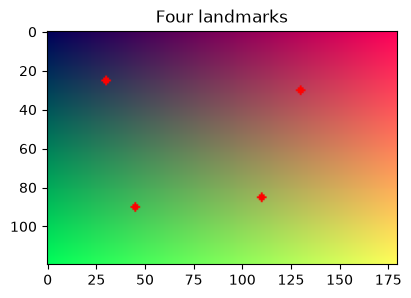

([[25.0, 30.0]], (120, 180))


In [2]:
rows, columns = np.indices((120, 180))
pixels = np.stack((columns / 179, rows / 119, np.full(rows.shape, .35)), axis=-1)
image = ImageLand(pixels)

marks = MarksLand([[25, 30], [30, 130], [85, 110], [90, 45]], shape=image.shape)
(image + marks).show('Four landmarks')
print(marks[0].to_list())

### 2. Define regions in pixels or fractions

`relative` converts fractions once. `expand(1.2)` enlarges a rectangle around its center. `subscription` is the historical name for intersection; it returns None when regions do not overlap.

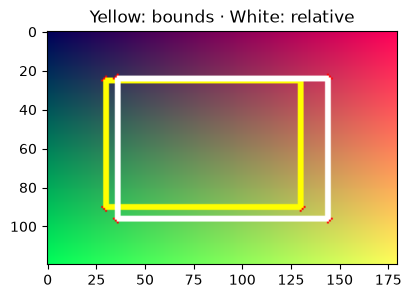

Area: 6500.0 Center: [57.5, 80.0] Intersection: 6110.0


In [3]:
box = marks.to_square()
relative = SquareMarks.relative(.2, .8, .2, .8, shape=image.shape)
intersection = box.subscription(relative)
outlined = image + box
outlined.ADDED_LINES_COLOR = (255, 255, 255)
(outlined + relative).show('Yellow: bounds · White: relative');
print('Area:', box.area(), 'Center:', box.center(), 'Intersection:', intersection.area())

### 3. Measure a vector and combine sets

Angles are counterclockwise from the rightward horizontal direction. `length()` and the legacy spelling `lenght()` are equivalent. Union and subtraction operate on point membership and leave both operands unchanged.

The yellow box encloses our landmarks; the white rectangle comes from fractional canvas coordinates. Their overlap is the region shared by both.

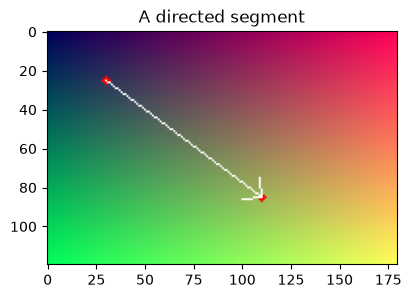

Length: 100.0 Angle: -36.87


In [4]:
vector = DualMarks(marks[0], marks[2], shape=image.shape)
(image + vector).show('A directed segment')
print('Length:', round(vector.length(), 2), 'Angle:', round(vector.angle(), 2))
remaining = marks - marks[0]
combined = remaining + marks[0]

## Checks

In [5]:
assert marks.get_marks().shape == (4, 2)
assert remaining.get_marks().shape == (3, 2)
assert combined.get_marks().shape == (4, 2)
assert vector.length() > 0
assert box.area() > 0

## Take it further 🚀

A region tells us where. Next, turn that region into a mask that controls **how much** color each pixel receives.

[Choose the next notebook](https://github.com/bateni1380/landpy/tree/master/tutorials)

**Try it:** Move one landmark. How do the bounding box and vector change?

➡️ **[Continue to notebook 3](https://github.com/bateni1380/landpy/blob/master/tutorials/3-heat-maps-and-filters.ipynb)**

[← Previous lesson](https://github.com/bateni1380/landpy/blob/master/tutorials/1-images-and-coordinates.ipynb)